In [34]:
#%pip install matplotlib seaborn

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

# 1. Читаем файлы, явно указав разделитель ';'
df1 = pd.read_csv('winequality-red.csv', sep=';')
df2 = pd.read_csv('winequality-white.csv', sep=';')

# 2. Полезный шаг: добавляем маркер, чтобы не потерять тип вина
df1['type'] = 'red'
df2['type'] = 'white'

# 3. Склеиваем по вертикали
result = pd.concat([df1, df2], ignore_index=True)

# 4. Сохраняем результат (тоже можно использовать ';', чтобы Excel открыл корректно)
result.to_csv('merged.csv', sep=';', index=False)

In [36]:
import pandas as pd
import numpy as np


data = pd.read_csv("merged.csv", sep=";")
data.head()

#data.info()
#data.describe()
#data['type'].value_counts()
#data.duplicated().sum()

#clean = data.drop_duplicates()
#data.describe() - clean.describe()


#data['quality'].value_counts().sort_index()






,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [37]:
data.isna().sum().sum()

np.int64(0)

In [38]:
data.groupby('quality')['sulphates'].mean()

quality
3    0.506333
4    0.505648
5    0.526403
6    0.532549
7    0.547025
8    0.512487
9    0.466000
Name: sulphates, dtype: float64

In [39]:
data.groupby('quality')['sulphates'].agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
quality,,,,
3,30,0.506333,0.505,0.126994
4,216,0.505648,0.485,0.164434
5,2138,0.526403,0.500,0.141648
6,2836,0.532549,0.510,0.146741
7,1079,0.547025,0.520,0.160436
8,193,0.512487,0.480,0.165891
9,5,0.466000,0.460,0.092628


<Axes: xlabel='quality', ylabel='sulphates'>

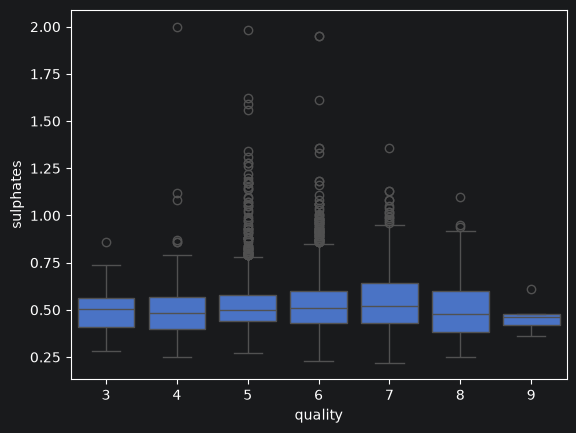

In [40]:
sns.boxplot(x='quality', y='sulphates', data=data)

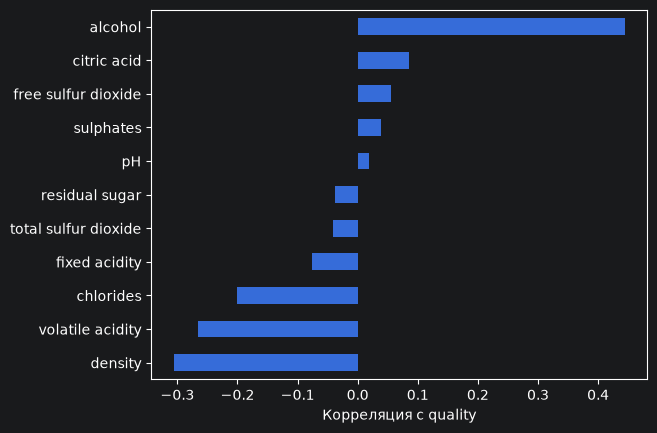

np.float64(0.4443185200076552)

In [41]:
import matplotlib.pyplot as plt

corr = data.corr(numeric_only=True)['quality'].drop('quality').sort_values()
corr.plot.barh()
plt.xlabel('Корреляция с quality')
plt.show()

corr['alcohol']

In [42]:
# начнем проверять алкоголь
data['alcohol'].describe()

count    6497.000000
mean       10.491801
std         1.192712
min         8.000000
25%         9.500000
50%        10.300000
75%        11.300000
max        14.900000
Name: alcohol, dtype: float64

In [43]:
#без дубликатов
clean = data.drop_duplicates()
clean['alcohol'].corr(clean['quality'])


np.float64(0.4694218379411507)

In [44]:
#тенленция по группам
data.groupby('quality')['alcohol'].agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
quality,,,,
3,30,10.215000,10.15,1.106497
4,216,10.180093,10.00,0.985923
5,2138,9.837783,9.60,0.814416
6,2836,10.587553,10.50,1.126491
7,1079,11.386006,11.40,1.199337
8,193,11.678756,12.00,1.278921
9,5,12.180000,12.50,1.013410


In [45]:
#проверка по карсный и белым винам
red = data[data['type'] == 'red']
white = data[data['type'] == 'white']

corr_red = red.corr(numeric_only=True)['quality'].drop('quality')
corr_white = white.corr(numeric_only=True)['quality'].drop('quality')

print('red:', corr_red['alcohol'])
print('white:', corr_white['alcohol'])

red: 0.47616632400113656
white: 0.4355747154613733


np.float64(-0.6867454216821351)

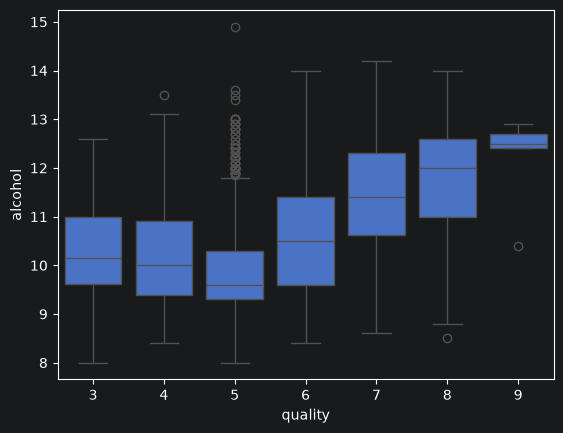

In [46]:
sns.boxplot(x='quality', y='alcohol', data=data)      # график к таблице по группам
data['alcohol'].corr(data['quality'], method='spearman')
data['alcohol'].corr(data['density'])                  # важная

Корреляция с quality: -0.306
  red:   -0.175
  white: -0.307


,count,mean,median,std
quality,,,,
3,30,0.995744,0.995900,0.002833
4,216,0.994833,0.994995,0.002475
5,2138,0.995849,0.996100,0.002439
6,2836,0.994558,0.994700,0.003035
7,1079,0.993126,0.992400,0.003020
8,193,0.992514,0.991890,0.002880
9,5,0.991460,0.990300,0.003118


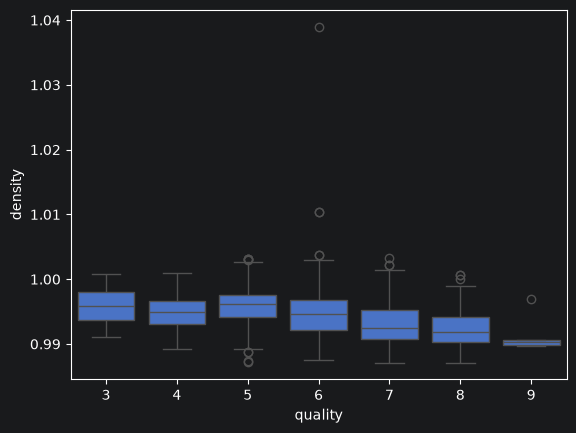

np.float64(-0.686745421682135)

In [47]:
def check_feature(col):
    print('Корреляция с quality:', round(data[col].corr(data['quality']), 3))
    print('  red:  ', round(red[col].corr(red['quality']), 3))
    print('  white:', round(white[col].corr(white['quality']), 3))
    display(data.groupby('quality')[col].agg(['count', 'mean', 'median', 'std']))
    sns.boxplot(x='quality', y=col, data=data)
    plt.show()


check_feature('density')
data['density'].corr(data['alcohol'])

Корреляция с quality: -0.266
  red:   -0.391
  white: -0.195


,count,mean,median,std
quality,,,,
3,30,0.517000,0.415,0.341913
4,216,0.457963,0.380,0.229311
5,2138,0.389614,0.330,0.178582
6,2836,0.313863,0.270,0.147080
7,1079,0.288800,0.270,0.116797
8,193,0.291010,0.280,0.119357
9,5,0.298000,0.270,0.057619


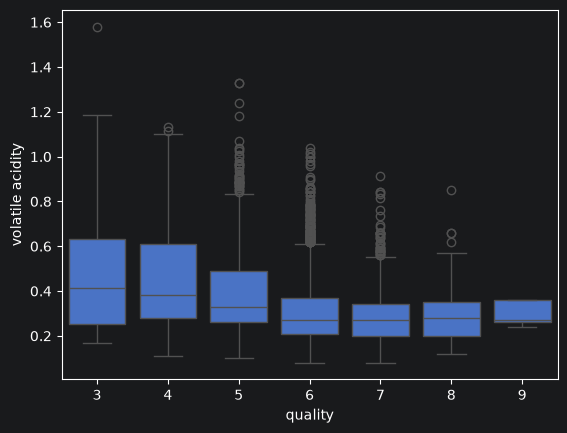

np.float64(-0.037640385838728745)

In [48]:
check_feature('volatile acidity')
data['volatile acidity'].corr(data['alcohol'])

Quality от 3-8, белых вин больше, дубликатов больше 1000(весьма много, могут влиять на веса, но должны не сильно). None нету в таблице. Оценки 6 ставили чаще всего. На крайних(3 и 9) будет не так много для обучения. Сульфаты имеют маленький разброс, поэтому по ним не стоит смотреть: разница между группами намного меньше разброса внутри групп
Чтобы проверить, не создают ли дубликаты искусственную связь, корреляцию alcohol с quality посчитали с дубликатами и без. Плотность очень завивсит от алкоголя
А вот кислотность так же влияет на качество, но от алекоголя почти не корелирует

In [49]:
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [50]:
from sklearn.model_selection import train_test_split

df = data.drop_duplicates().copy()
df['type'] = (df['type'] == 'red').astype(int)
X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10, stratify=y # учим находить x по y
)


print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).sort_index())
print(y_test.value_counts(normalize=True).sort_index())

(4256, 12) (1064, 12)
quality
3    0.005639
4    0.038769
5    0.329417
6    0.436560
7    0.160949
8    0.027726
9    0.000940
Name: proportion, dtype: float64
quality
3    0.005639
4    0.038534
5    0.328947
6    0.437030
7    0.160714
8    0.028195
9    0.000940
Name: proportion, dtype: float64


In [51]:
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print('Dummy RMSE:', root_mean_squared_error(y_test, y_pred_dummy))
print('Dummy MAE:', mean_absolute_error(y_test, y_pred_dummy))

Dummy RMSE: 0.8801023384558065
Dummy MAE: 0.694789576149019


In [52]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

linreg = Pipeline([
    ('scaler', StandardScaler()),
    ('regression', LinearRegression())
])
linreg.fit(X_train, y_train)
pred_train = linreg.predict(X_train)
pred_test = linreg.predict(X_test)

print('Train RMSE:', root_mean_squared_error(y_train, pred_train))
print('Test RMSE:', root_mean_squared_error(y_test, pred_test))
print('Test MAE:', mean_absolute_error(y_test, pred_test))

Train RMSE: 0.730884368542938
Test RMSE: 0.729681228503428
Test MAE: 0.5664045246524688


Text(0.5, 0, 'coefficient')

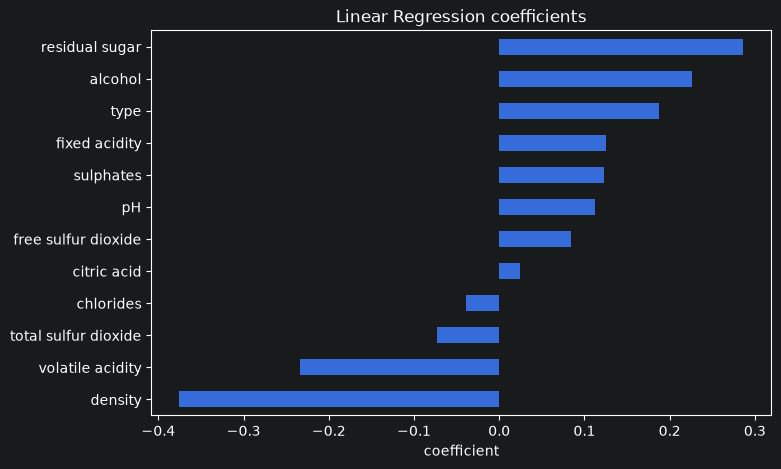

In [53]:
coef = pd.Series(linreg[-1].coef_, index=X.columns)
coef = coef.sort_values()

ax = coef.plot(kind="barh", figsize=(8, 5))
ax.set_title("Linear Regression coefficients")
ax.set_xlabel("coefficient")

Сахар, алкоголь, плотность и кислотности получили весьма большие веса для модели

In [54]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=10, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred_train = rf.predict(X_train)
rf_pred_test = rf.predict(X_test)

print('Train RMSE:', root_mean_squared_error(y_train, rf_pred_train))
print('Test RMSE:', root_mean_squared_error(y_test, rf_pred_test))
print('Test MAE:', mean_absolute_error(y_test, rf_pred_test))

Train RMSE: 0.25937981810000943
Test RMSE: 0.6955883402543089
Test MAE: 0.5303853383458645


По разнице с трейн и тест можно легко заметить переобучение модели

In [55]:
for depth in [4, 6, 8, 10, 12, 15, 20, None]:
    rf = RandomForestRegressor(random_state=42, n_jobs=-1, max_depth=depth)
    scores = cross_val_score(rf, X_train, y_train, cv=5,
                             scoring='neg_root_mean_squared_error')
    print(depth, round(-scores.mean(), 4), round(scores.std(), 4))

4 0.7352 0.0185
6 0.7155 0.0179
8 0.7045 0.0185
10 0.6993 0.018
12 0.6973 0.0183
15 0.6975 0.0179
20 0.6975 0.0186
None 0.697 0.0182


Глубины дервьев в 12 вполне хватает

Text(0.5, 0, 'importance')

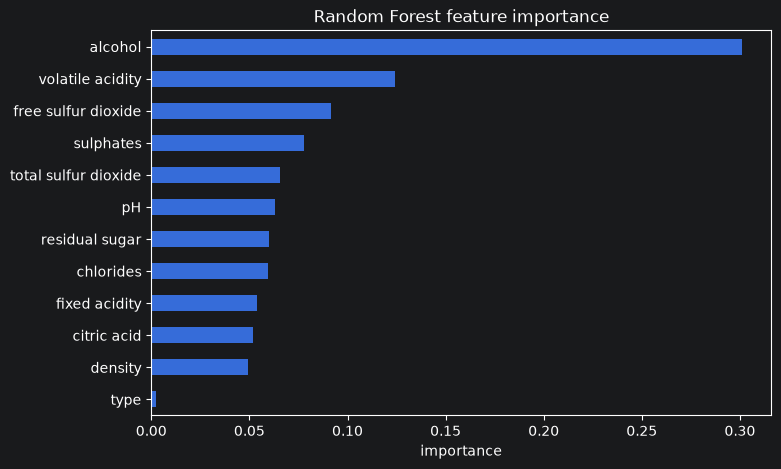

In [56]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=10, n_jobs=-1, max_depth=12)
rf.fit(X_train, y_train)

rf_pred_train = rf.predict(X_train)
rf_pred_test = rf.predict(X_test)


importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

ax = importance.plot(kind="barh", figsize=(8, 5))
ax.set_title("Random Forest feature importance")
ax.set_xlabel("importance")

Плотность очень влияет от алкоголя, поэтому важность могла размыться. Кислотность осталось так же вадной, как мы и думали. Сахар ушел из важных признаков

In [57]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(random_state=10)
gb.fit(X_train, y_train)

print('Train RMSE:', root_mean_squared_error(y_train, gb.predict(X_train)))
print('Test RMSE:', root_mean_squared_error(y_test, gb.predict(X_test)))
print('Test MAE:', mean_absolute_error(y_test, gb.predict(X_test)))

Train RMSE: 0.6407173583842456
Test RMSE: 0.7044666372605034
Test MAE: 0.5468620105565917


In [58]:
params = {
    'n_estimators': [300, 600],
    'learning_rate': [0.02, 0.05],
    'max_depth': [4, 5, 6],
    'subsample': [0.8, 1.0],
    'min_samples_leaf': [1, 10],
}
search = GridSearchCV(GradientBoostingRegressor(random_state=10),
                      params, cv=5, scoring='neg_root_mean_squared_error',
                      n_jobs=-1)
search.fit(X_train, y_train)
print(search.best_params_, -search.best_score_)

{'learning_rate': 0.02, 'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 300, 'subsample': 0.8} 0.6903053662151895


In [59]:
gb = GradientBoostingRegressor(random_state=10, n_estimators=300, learning_rate=0.02, max_depth=5, subsample =0.8, min_samples_leaf=1)
gb.fit(X_train, y_train)

print('Train RMSE:', root_mean_squared_error(y_train, gb.predict(X_train)))
print('Test RMSE:', root_mean_squared_error(y_test, gb.predict(X_test)))
print('Test MAE:', mean_absolute_error(y_test, gb.predict(X_test)))

Train RMSE: 0.563325563615438
Test RMSE: 0.6959686817556733
Test MAE: 0.5401407224958551


Text(0.5, 0, 'importance')

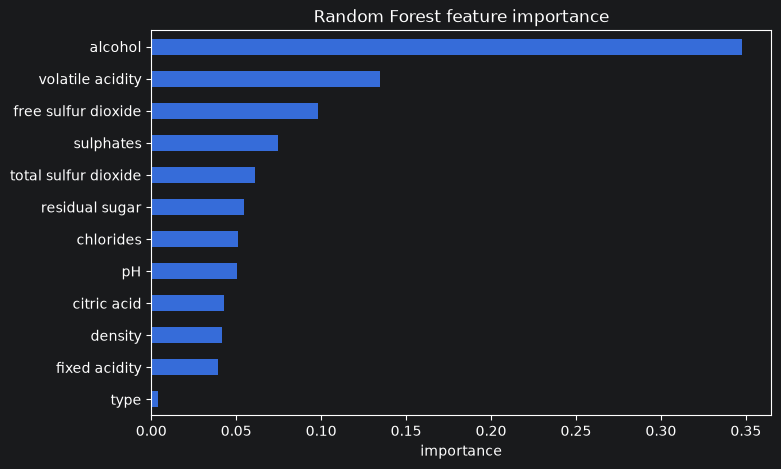

In [60]:



importance = pd.Series(gb.feature_importances_, index=X.columns).sort_values()

ax = importance.plot(kind="barh", figsize=(8, 5))
ax.set_title("Random Forest feature importance")
ax.set_xlabel("importance")

In [61]:
imp = pd.DataFrame({
    'RF': rf.feature_importances_,
    'GB': gb.feature_importances_,
}, index=X.columns)

imp['Linear |coef|'] = coef.abs() / coef.abs().sum()   # нормируем, чтобы сумма = 1, как у деревьев
imp = imp.sort_values('RF', ascending=False)
imp.round(3)

,RF,GB,Linear |coef|
alcohol,0.301,0.348,0.120
volatile acidity,0.124,0.135,0.124
free sulfur dioxide,0.092,0.098,0.045
sulphates,0.078,0.074,0.065
total sulfur dioxide,0.066,0.061,0.038
pH,0.063,0.050,0.060
residual sugar,0.060,0.055,0.151
chlorides,0.059,0.051,0.021
fixed acidity,0.054,0.039,0.066
citric acid,0.052,0.043,0.013


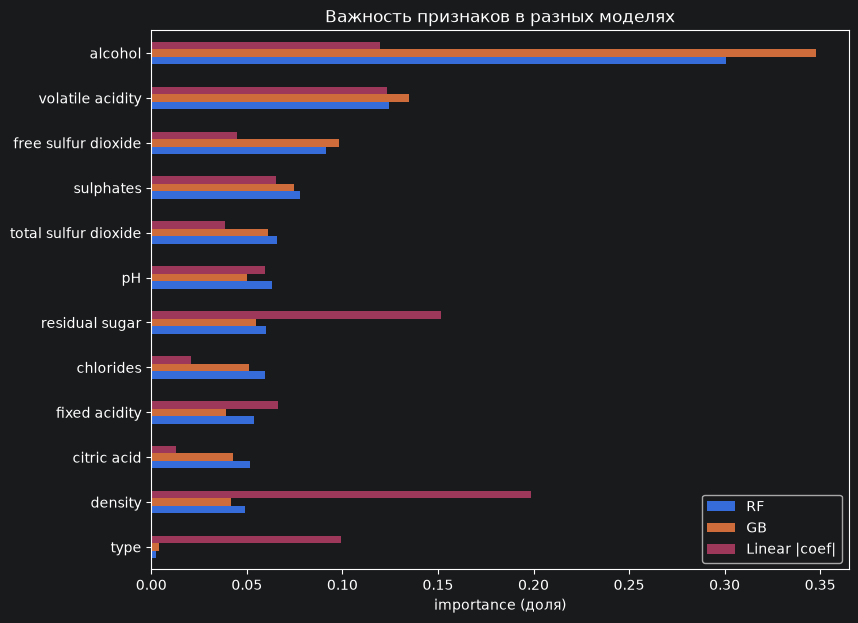

In [62]:
imp.sort_values('RF').plot(kind='barh', figsize=(9, 7))
plt.title('Важность признаков в разных моделях')
plt.xlabel('importance (доля)')
plt.show()

Нет. Feature importance показывает, насколько признак полезен конкретной модели для предсказания на имеющихся данных, но не объясняет, почему качество меняется. Причин несколько - можно заметить что разные модели по одному признаку дают разную важность, признаки связанные друг с другом делят важность между собой

In [63]:
best = rf

errors = X_test.copy()
errors['true'] = y_test
errors['pred'] = best.predict(X_test)
errors['error'] = errors['pred'] - errors['true']      # >0 — завысила, <0 — занизила
errors['abs_error'] = errors['error'].abs()
errors.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type,true,pred,error,abs_error
4112,6.9,0.340,0.36,1.4,0.032,13.0,145.0,0.99214,3.07,0.52,9.8,0,5,5.437623,0.437623,0.437623
4732,6.6,0.250,0.35,2.9,0.034,38.0,121.0,0.99008,3.19,0.40,12.8,0,6,6.857830,0.857830,0.857830
2205,7.3,0.250,0.29,7.5,0.049,38.0,158.0,0.99650,3.43,0.38,9.6,0,5,5.492296,0.492296,0.492296
378,11.4,0.625,0.66,6.2,0.088,6.0,24.0,0.99880,3.11,0.99,13.3,1,6,7.123981,1.123981,1.123981
5800,6.7,0.410,0.27,2.6,0.033,25.0,85.0,0.99086,3.05,0.34,11.7,0,6,6.342776,0.342776,0.342776


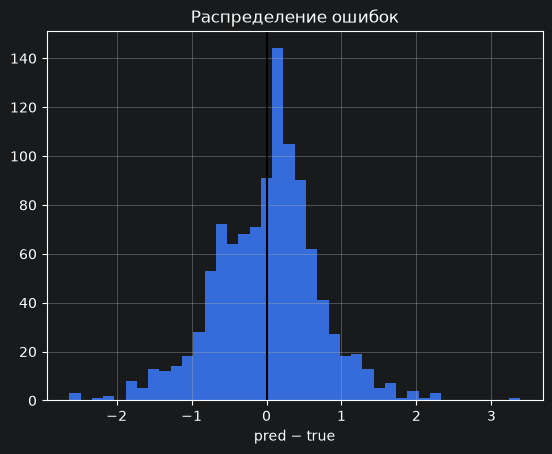

count    1064.000000
mean        0.009605
std         0.697330
min        -2.631494
25%        -0.436559
50%         0.084884
75%         0.418801
max         3.384461
Name: error, dtype: float64

In [64]:
errors['error'].hist(bins=40)
plt.axvline(0, color='black')
plt.xlabel('pred − true')
plt.title('Распределение ошибок')
plt.show()

errors['error'].describe()

In [66]:
features = ['alcohol', 'volatile acidity', 'sulphates', 'free sulfur dioxide', 'chlorides', 'residual sugar']
typical = df.groupby('quality')[features].median()

worst = errors.sort_values('abs_error', ascending=False).head(10)
worst[['true', 'pred', 'error', 'alcohol', 'volatile acidity', 'type']]

def explain(i):
    row = errors.loc[i]
    print(f"Вино {i}: true = {row['true']}, pred = {row['pred']:.2f}, type = {'red' if row['type'] else 'white'}")
    display(pd.DataFrame({
        'это вино': row[features],
        f"типичное для {int(row['true'])}": typical.loc[int(row['true'])],
        f"типичное для {round(row['pred'])}": typical.loc[round(row['pred'])],
    }))

explain(2828)
explain(3005)
explain(459)

Вино 2828: true = 3.0, pred = 6.38, type = white


,это вино,типичное для 3,типичное для 6
alcohol,12.400,10.150,10.500
volatile acidity,0.330,0.415,0.270
sulphates,0.320,0.505,0.520
free sulfur dioxide,18.000,17.000,29.000
chlorides,0.033,0.055,0.046
residual sugar,1.150,3.150,2.800


Вино 3005: true = 8.0, pred = 5.47, type = white


,это вино,типичное для 8,типичное для 5
alcohol,10.500,12.2000,9.600
volatile acidity,0.220,0.2800,0.340
sulphates,0.380,0.4900,0.510
free sulfur dioxide,12.000,32.0000,27.000
chlorides,0.034,0.0365,0.053
residual sugar,6.800,3.8000,2.800


Вино 459: true = 3.0, pred = 5.32, type = red


,это вино,типичное для 3,типичное для 5
alcohol,9.000,10.150,9.600
volatile acidity,0.580,0.415,0.340
sulphates,0.570,0.505,0.510
free sulfur dioxide,10.000,17.000,27.000
chlorides,0.074,0.055,0.053
residual sugar,2.200,3.150,2.800


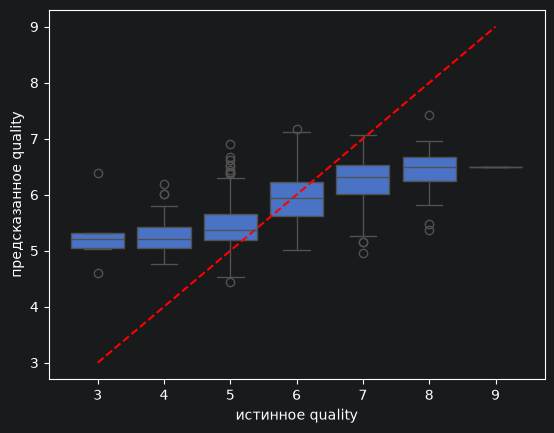

In [67]:
sns.boxplot(x='true', y='pred', data=errors)
plt.plot([0, 6], [3, 9], color='red', linestyle='--')   # идеальная линия: pred = true
plt.xlabel('истинное quality')
plt.ylabel('предсказанное quality')
plt.show()

In [68]:
by_q = errors.groupby('true').agg(
    count=('error', 'size'),
    mean_error=('error', 'mean'),
    MAE=('abs_error', 'mean'),
)
by_q['RMSE'] = errors.groupby('true')['error'].apply(lambda e: np.sqrt((e**2).mean()))
by_q

,count,mean_error,MAE,RMSE
true,,,,
3,6,2.291188,2.291188,2.354498
4,41,1.286989,1.286989,1.330958
5,350,0.441710,0.457445,0.572281
6,465,-0.071719,0.351254,0.428523
7,171,-0.747657,0.749591,0.856427
8,30,-1.573050,1.573050,1.626968
9,1,-2.502232,2.502232,2.502232


In [69]:
by_q = errors.groupby('true').agg(
    count=('error', 'size'),
    mean_error=('error', 'mean'),
    MAE=('abs_error', 'mean'),
)
by_q['RMSE'] = errors.groupby('true')['error'].apply(lambda e: np.sqrt((e**2).mean()))
by_q

,count,mean_error,MAE,RMSE
true,,,,
3,6,2.291188,2.291188,2.354498
4,41,1.286989,1.286989,1.330958
5,350,0.441710,0.457445,0.572281
6,465,-0.071719,0.351254,0.428523
7,171,-0.747657,0.749591,0.856427
8,30,-1.573050,1.573050,1.626968
9,1,-2.502232,2.502232,2.502232


Модель хорошо определяет средние оценки(5-7), чем ближе к окраиными тем хуже(это может быть связанно с тем, что в граничных данных сильно меньше чем центральных, там может быть сильно больше выбросов)